In [1]:
from ase.io import read, write
from ase import units
from ase.visualize import view
import numpy as np
from imolcraft.crafter.ffxml import merge_xml
from imolcraft.trainer import DistanceTrainer
from imolcraft.calculator.distance import DistanceCalculator
from imolcraft.trainer.loss import loss_energy
from functools import partial

Warning on use of the timeseries module: If the inherent timescales of the system are long compared to those being analyzed, this statistical inefficiency may be an underestimate.  The estimate presumes the use of many statistically independent samples.  Tests should be performed to assess whether this condition is satisfied.   Be cautious in the interpretation of the data.


In [2]:
atoms_snli = read("SNLi.log")

In [3]:
merged_xml = merge_xml(["SN.xml", "Li.xml"], "merged.xml")  # written to xmlfiles/merged.xml

In [4]:
view(atoms_snli)

<Popen: returncode: None args: ['/Users/srak/miniconda3/envs/imc_cpu/bin/pyt...>

In [5]:
calculator = DistanceCalculator(
    atoms_snli,
    1,
    "cn__Li",
    scan_idx=[[5,10]],
    directory="distance_scan",
    qmparams={
             "method": "wb97xd",
             "basis": "6-31g(d)",
             "opt": "modredundant",
             }
)

In [6]:
# calculator.do_qmscan()# 

In [7]:
import glob

g16logs = glob.glob("distance_scan/*.log")

In [8]:
for i, g16log in enumerate(g16logs):
    atoms = read(g16log)
    distance = atoms.get_distance(5, 10)
    energy = atoms.get_potential_energy()/(units.kJ / units.mol)
    calculator.qm_scan[0]["distance_A"].append(distance)
    calculator.qm_scan[0]["energy_kjmol"].append(energy)
    calculator.qm_scan[0]["atoms"].append(atoms)

In [9]:
# calculator.qm_scan[0]でcalculator.qm_scan[0]["distance_A"]ベースでソート
# "distance_A"の値で全リストをソート
order = np.argsort(calculator.qm_scan[0]["distance_A"])
for key in calculator.qm_scan[0]:
	calculator.qm_scan[0][key] = [calculator.qm_scan[0][key][i] for i in order]

In [10]:
calculator.do_ffscan(merged_xml)

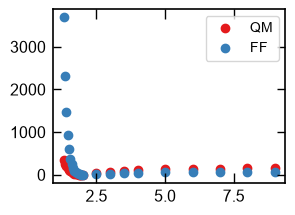

In [11]:
import numpy as np
import matplotlib.pyplot as plt

plt.scatter(calculator.qm_scan[0]["distance_A"], np.array(calculator.qm_scan[0]["energy_kjmol"])-np.array(calculator.qm_scan[0]["energy_kjmol"]).min(), label="QM")

plt.scatter(calculator.ff_scan[0]["distance_A"], np.array(calculator.ff_scan[0]["energy_kjmol"])-np.array(calculator.ff_scan[0]["energy_kjmol"]).min(), label="FF")

plt.legend()

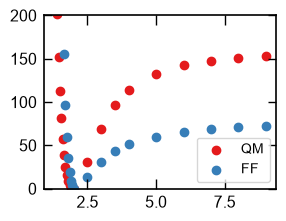

In [12]:
import numpy as np
import matplotlib.pyplot as plt

plt.ylim(0,200)
plt.scatter(calculator.qm_scan[0]["distance_A"], np.array(calculator.qm_scan[0]["energy_kjmol"])-np.array(calculator.qm_scan[0]["energy_kjmol"]).min(), label="QM")

plt.scatter(calculator.ff_scan[0]["distance_A"], np.array(calculator.ff_scan[0]["energy_kjmol"])-np.array(calculator.ff_scan[0]["energy_kjmol"]).min(), label="FF")

plt.legend()

In [13]:
len(calculator.qm_scan[0]["energy_kjmol"])

24

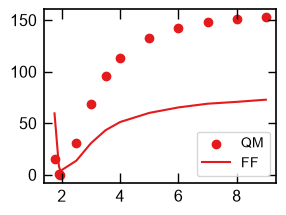

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# plt.ylim(0,400)
dihed_idx = [9, 12, 13, 15, 16,17,18,19,20,21,22,23]
plt.scatter(np.array(calculator.qm_scan[0]["distance_A"])[dihed_idx], 
            np.array(calculator.qm_scan[0]["energy_kjmol"])[dihed_idx]-np.array(calculator.qm_scan[0]["energy_kjmol"]).min(), label="QM")

plt.plot(np.array(calculator.ff_scan[0]["distance_A"])[dihed_idx], 
            np.array(calculator.ff_scan[0]["energy_kjmol"])[dihed_idx]-np.array(calculator.ff_scan[0]["energy_kjmol"]).min(), label="FF")

plt.legend()

In [15]:
calculator.qm_scan[0]["energy_kjmol"] = np.array(calculator.qm_scan[0]["energy_kjmol"])[dihed_idx]
calculator.qm_scan[0]["distance_A"] = np.array(calculator.qm_scan[0]["distance_A"])[dihed_idx]
calculator.qm_scan[0]["atoms"] = [calculator.qm_scan[0]["atoms"][i] for i in dihed_idx]

calculator.ff_scan[0]["energy_kjmol"] = np.array(calculator.ff_scan[0]["energy_kjmol"])[dihed_idx]
calculator.ff_scan[0]["distance_A"] = np.array(calculator.ff_scan[0]["distance_A"])[dihed_idx]
calculator.ff_scan[0]["atoms"] = [calculator.ff_scan[0]["atoms"][i] for i in dihed_idx]

In [16]:
lossfn = partial(loss_energy, 
                 weight_scheme="uniform", 
                 zeropoint="qmmin")

In [17]:
# initial.pdb holds the SN-Li pair with CONECT records (the same file as in ../distance_vsite)

In [18]:
dtrainer = DistanceTrainer(ffxml_list=["SN.xml", "Li.xml"], 
                           nums_ffxml=[1,1], 
                           pdbfile="initial.pdb", 
                           calculator=calculator,
                           loss_fn=lossfn,
                           opt_fftypes=["NonbondedForce/charge", "NonbondedForce/sigma"],
                           lr=0.005)

In [19]:
dtrainer.ffparams

{'HarmonicBondForce': {'length': Array([0.1153, 0.1467, 0.1538, 0.1097], dtype=float64),
  'k': Array([746040.672, 247575.648, 194572.736, 314569.856], dtype=float64)},
 'HarmonicAngleForce': {'angle': Array([3.11680898, 1.94970731, 1.90956473, 1.91637152, 1.87762521],      dtype=float64),
  'k': Array([612.671488, 554.597568, 409.019472, 391.756288, 326.01728 ],      dtype=float64)},
 'PeriodicTorsionForce': {'proper_phase': Array([3.14159265, 3.14159265, 0.        , 0.        , 0.        ],      dtype=float64),
  'proper_k': Array([0.        , 0.        , 0.65084444, 0.65084444, 0.50208   ],      dtype=float64),
  'improper_phase': Array([], shape=(0,), dtype=float64),
  'improper_k': Array([], shape=(0,), dtype=float64)},
 'NonbondedForce': {'sigma': Array([0.32735182, 0.34789595, 0.33977095, 0.2600177 , 0.20259037],      dtype=float64),
  'epsilon': Array([0.4594032, 0.6677664, 0.4510352, 0.0870272, 0.0765672], dtype=float64),
  'charge': Array([-0.4450872,  0.2965618, -0.0415062, 

In [20]:
from imolcraft.trainer.dmff_utils import neutralize

def grad_modify(grads):
    grads["NonbondedForce"]["charge"] = grads["NonbondedForce"]["charge"].at[10].set(0.0)
    return grads

def ffparams_modify(ffparams):
    ffparams = neutralize(ffparams, dtrainer.natoms_list, nc=0.8, target_lists=[[0,1,2,3,4,5,6,7,8,9]], target_charges=[0.0])

    return ffparams

In [21]:
dtrainer.add_modifyfn("after_grad", grad_modify)
dtrainer.add_modifyfn("after_update", ffparams_modify)

In [22]:
dtrainer.setup()

/Users/srak/miniconda3/envs/imc_cpu/lib/python3.11/site-packages/dmff/common/nblist.py:306: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=2`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  nblist = np.array(list(permutations(range(natoms), 2)), dtype=np.dtype(int, 2))


In [23]:
dtrainer.fit(steps=300, checkpoint_frequency=10)

grad obtained.... Memory Usage: 1014.09 MB
grad modify.... Memory Usage: 1020.78 MB


update finished.... Memory Usage: 1081.88 MB
Epoch 0, Loss: 1.075965472237297, Memory Usage: 1083.25 MB
Loss:  1.075965472237297
Best Loss:  1.075965472237297 at epoch  0
Epoch 0 completed in 3.27 seconds.
----
grad obtained.... Memory Usage: 1083.47 MB
grad modify.... Memory Usage: 1083.47 MB
update finished.... Memory Usage: 1083.48 MB
Loss:  0.899109620619422
Best Loss:  0.899109620619422 at epoch  1
Epoch 1 completed in 0.04 seconds.
----
grad obtained.... Memory Usage: 1085.06 MB
grad modify.... Memory Usage: 1085.06 MB
update finished.... Memory Usage: 1085.09 MB
Loss:  0.7785006282612265
Best Loss:  0.7785006282612265 at epoch  2
Epoch 2 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1085.30 MB
grad modify.... Memory Usage: 1085.30 MB
update finished.... Memory Usage: 1085.30 MB
Loss:  0.6960763237899998
Best Loss:  0.6960763237899998 at epoch  3
Epoch 3 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1085.39 MB
grad modify.... Memory Usage: 1085

grad obtained.... Memory Usage: 1085.77 MB
grad modify.... Memory Usage: 1085.77 MB
update finished.... Memory Usage: 1085.81 MB
Loss:  0.5714346573427831
Best Loss:  0.5714346573427831 at epoch  6
Epoch 6 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1085.81 MB
grad modify.... Memory Usage: 1085.81 MB
update finished.... Memory Usage: 1085.81 MB
Loss:  0.5511733447074038
Best Loss:  0.5511733447074038 at epoch  7
Epoch 7 completed in 0.04 seconds.
----
grad obtained.... Memory Usage: 1085.81 MB
grad modify.... Memory Usage: 1085.81 MB
update finished.... Memory Usage: 1085.81 MB
Loss:  0.5363590001405655
Best Loss:  0.5363590001405655 at epoch  8
Epoch 8 completed in 0.03 seconds.
----
grad obtained.... Memory Usage: 1085.89 MB
grad modify.... Memory Usage: 1085.89 MB
update finished.... Memory Usage: 1085.89 MB
Loss:  0.5253721107750461
Best Loss:  0.5253721107750461 at epoch  9
Epoch 9 completed in 0.08 seconds.
----
grad obtained.... Memory Usage: 1085.89 MB
grad 

grad obtained.... Memory Usage: 1085.88 MB
grad modify.... Memory Usage: 1085.88 MB
update finished.... Memory Usage: 1085.88 MB
Loss:  0.5108425658939868
Best Loss:  0.5108425658939868 at epoch  11
Epoch 11 completed in 0.03 seconds.
----
grad obtained.... Memory Usage: 1085.95 MB
grad modify.... Memory Usage: 1085.95 MB
update finished.... Memory Usage: 1085.95 MB
Loss:  0.5060237602760845
Best Loss:  0.5060237602760845 at epoch  12
Epoch 12 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1085.95 MB
grad modify.... Memory Usage: 1085.95 MB
update finished.... Memory Usage: 1085.95 MB
Loss:  0.5022900903506093
Best Loss:  0.5022900903506093 at epoch  13
Epoch 13 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 1086.00 MB
grad modify.... Memory Usage: 1086.00 MB
update finished.... Memory Usage: 1086.00 MB
Loss:  0.4993755528631076
Best Loss:  0.4993755528631076 at epoch  14
Epoch 14 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1086.00 

Loss:  0.49183110506963523
Best Loss:  0.49183110506963523 at epoch  19
Epoch 19 completed in 3.41 seconds.
----
grad obtained.... Memory Usage: 1101.41 MB
grad modify.... Memory Usage: 1101.41 MB
update finished.... Memory Usage: 1101.41 MB
Epoch 20, Loss: 0.49369006659924625, Memory Usage: 1101.41 MB
Loss:  0.49369006659924625
Best Loss:  0.49183110506963523 at epoch  19
Epoch 20 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1101.52 MB
grad modify.... Memory Usage: 1101.52 MB
update finished.... Memory Usage: 1101.66 MB
Loss:  0.4931452574158124
Best Loss:  0.49183110506963523 at epoch  19
Epoch 21 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1101.73 MB
grad modify.... Memory Usage: 1101.73 MB
update finished.... Memory Usage: 1101.73 MB
Loss:  0.4927249023818102
Best Loss:  0.49183110506963523 at epoch  19
Epoch 22 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 1101.73 MB
grad modify.... Memory Usage: 1101.73 MB
update finished..

...

grad obtained.... Memory Usage: 969.28 MB
grad modify.... Memory Usage: 969.28 MB
update finished.... Memory Usage: 969.28 MB
Loss:  0.1960571400653291
Best Loss:  0.07964955956614378 at epoch  239
Epoch 275 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 969.28 MB
grad modify.... Memory Usage: 969.28 MB
update finished.... Memory Usage: 969.28 MB
Loss:  0.19415182995029362
Best Loss:  0.07964955956614378 at epoch  239
Epoch 276 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 969.28 MB
grad modify.... Memory Usage: 969.28 MB
update finished.... Memory Usage: 969.28 MB
Loss:  0.19232055535063286
Best Loss:  0.07964955956614378 at epoch  239
Epoch 277 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 969.28 MB
grad modify.... Memory Usage: 969.28 MB
update finished.... Memory Usage: 969.33 MB
Loss:  0.1905612384420869
Best Loss:  0.07964955956614378 at epoch  239
Epoch 278 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 969.33

Loss:  0.18887062686852632
Best Loss:  0.07964955956614378 at epoch  239
Epoch 279 completed in 10.51 seconds.
----
grad obtained.... Memory Usage: 990.53 MB
grad modify.... Memory Usage: 990.53 MB
update finished.... Memory Usage: 990.53 MB
Epoch 280, Loss: 0.19102665678132613, Memory Usage: 990.53 MB
Loss:  0.19102665678132613
Best Loss:  0.07964955956614378 at epoch  239
Epoch 280 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 990.62 MB
grad modify.... Memory Usage: 990.62 MB
update finished.... Memory Usage: 991.02 MB
Loss:  0.18984891107994104
Best Loss:  0.07964955956614378 at epoch  239
Epoch 281 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 991.02 MB
grad modify.... Memory Usage: 991.02 MB
update finished.... Memory Usage: 991.02 MB
Loss:  0.18867963046271902
Best Loss:  0.07964955956614378 at epoch  239
Epoch 282 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 991.02 MB
grad modify.... Memory Usage: 991.02 MB
update finished..

Loss:  0.17715179142044005
Best Loss:  0.07964955956614378 at epoch  239
Epoch 292 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 991.16 MB
grad modify.... Memory Usage: 991.16 MB
update finished.... Memory Usage: 991.16 MB
Loss:  0.17600823225665574
Best Loss:  0.07964955956614378 at epoch  239
Epoch 293 completed in 0.02 seconds.
----
grad obtained.... Memory Usage: 991.19 MB
grad modify.... Memory Usage: 991.19 MB
update finished.... Memory Usage: 991.19 MB
Loss:  0.1748665799376776
Best Loss:  0.07964955956614378 at epoch  239
Epoch 294 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 991.19 MB
grad modify.... Memory Usage: 991.19 MB
update finished.... Memory Usage: 991.19 MB
Loss:  0.17372697177310678
Best Loss:  0.07964955956614378 at epoch  239
Epoch 295 completed in 0.01 seconds.
----
grad obtained.... Memory Usage: 991.25 MB
grad modify.... Memory Usage: 991.25 MB
update finished.... Memory Usage: 991.25 MB
Loss:  0.17258952915228384
Best Loss:

Context leak detected, CoreAnalytics returned false
Context leak detected, CoreAnalytics returned false


Loss:  0.1691910836283444
Best Loss:  0.07964955956614378 at epoch  239
Epoch 299 completed in 9.74 seconds.
----


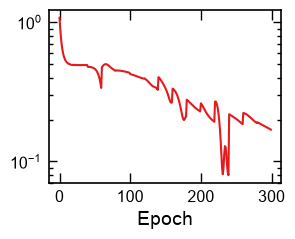

In [24]:
plt.yscale("log")
plt.xlabel("Epoch")
plt.plot(dtrainer.epochs, dtrainer.losses)

In [25]:
calculator.do_ffscan("SN1_Li1_best.xml")

In [26]:
np.array(calculator.qm_scan[0]["energy_kjmol"]).argmin()

np.int64(2)

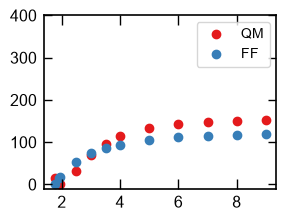

In [27]:
import numpy as np
import matplotlib.pyplot as plt

plt.ylim(-10,400)
plt.scatter(calculator.qm_scan[0]["distance_A"], np.array(calculator.qm_scan[0]["energy_kjmol"])-np.array(calculator.qm_scan[0]["energy_kjmol"]).min(), label="QM")

plt.scatter(calculator.ff_scan[0]["distance_A"], np.array(calculator.ff_scan[0]["energy_kjmol"])-np.array(calculator.ff_scan[0]["energy_kjmol"]).min(), label="FF")

plt.legend()